<a href="https://colab.research.google.com/github/Janith303/Sinhala-and-Maths-Model-training-/blob/main/notebooks/LR_Slow_Learner_Training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Logistic Regression — Slow Learner Identification (Maths)
A step-by-step notebook that trains **one model: Logistic Regression**, checks all evaluation metrics, and exports the model file.

**How to use in Colab:** Runtime → Run all. When Step 1 asks, upload `Maths_operation_data.xlsx`.

**What we predict:** `Slow` (positive class, = 1) vs `Normal` (= 0).

**Logistic Regression in one line:** it learns a weight for each feature and turns the weighted sum into a probability of being Slow (0–1). It is **easy to explain** — each weight tells you how a feature pushes the prediction towards Slow or Normal. It needs features on the same scale, so numbers are **standardised** first (done automatically inside the pipeline).

| Step | What happens |
|---|---|
| 1 | Load data |
| 2 | Look at the data |
| 3 | Choose features |
| 4 | Split into train / test |
| 5 | Train the Logistic Regression |
| 6 | Evaluate (Accuracy, Precision, Recall, F1, ROC-AUC …) |
| 7 | Cross-validation |
| 8 | Tune the model (C, penalty) |
| 9 | Understand the model (coefficients, odds ratios, threshold) |
| 10 | Save the model file and download |

## Step 1 — Load the data

In [1]:
import os, json, joblib, warnings
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, matthews_corrcoef, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, roc_curve)
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

FILE = 'Maths_operation_data.xlsx'
if not os.path.exists(FILE):
    from google.colab import files
    uploaded = files.upload()          # choose Maths_operation_data.xlsx
    FILE = list(uploaded.keys())[0]

df = pd.read_excel(FILE)
print('Rows, columns:', df.shape)
df.head()

Saving Maths operation data.xlsx to Maths operation data.xlsx
Rows, columns: (406, 7)


,No,Operation_Type,Total_Time,Carry_Over_Time,Erasure_Count,Hint_Requests,Student_Label
0,1,Addition,2.10,2.10,0,0,Normal
1,2,Addition,1.89,1.89,0,0,Normal
2,3,Addition,2.62,2.62,0,0,Normal
3,4,Addition,3.07,3.07,0,0,Normal
4,5,Division,8.20,8.20,0,0,Normal


## Step 2 — Look at the data

In [2]:
print('Missing values:'); print(df.isna().sum().to_string())
print('\nClass counts:'); print(df['Student_Label'].value_counts())
print('\nAverages per class:')
df.groupby('Student_Label')[['Total_Time','Carry_Over_Time','Erasure_Count','Hint_Requests']].mean().round(2)

Missing values:
No                 0
Operation_Type     0
Total_Time         0
Carry_Over_Time    0
Erasure_Count      0
Hint_Requests      0
Student_Label      0

Class counts:
Student_Label
Normal    234
Slow      172
Name: count, dtype: int64

Averages per class:


,Total_Time,Carry_Over_Time,Erasure_Count,Hint_Requests
Student_Label,,,,
Normal,10.54,9.17,0.05,0.0
Slow,86.82,69.91,0.91,0.5


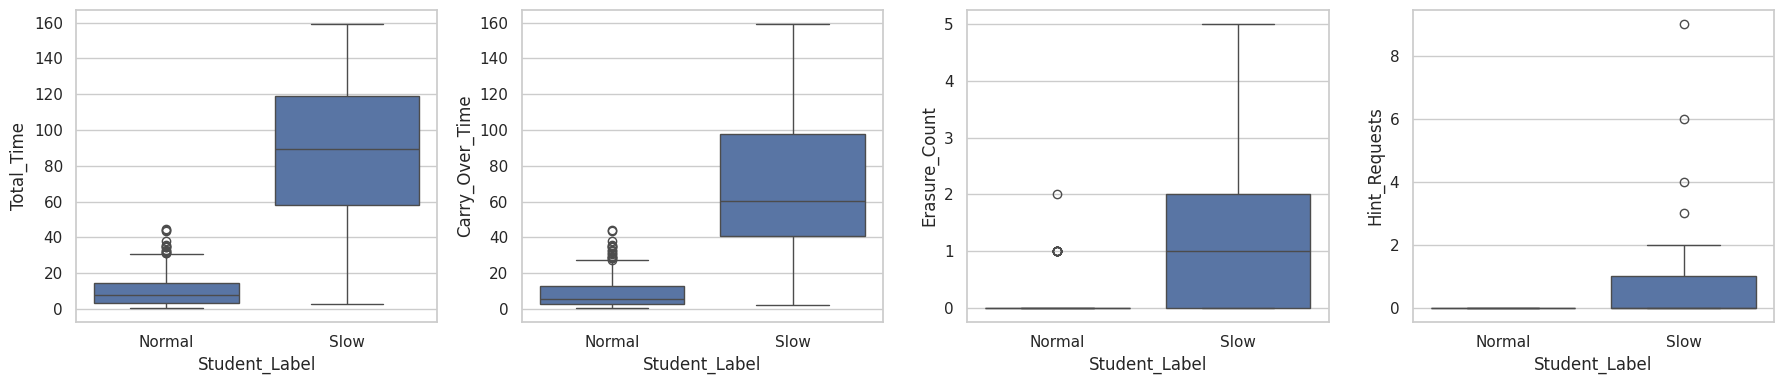

In [3]:
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
for a, col in zip(ax, ['Total_Time','Carry_Over_Time','Erasure_Count','Hint_Requests']):
    sns.boxplot(data=df, x='Student_Label', y=col, ax=a)
plt.tight_layout(); plt.show()

**Notice:** only about 21% of rows are `Slow`. *Accuracy alone is misleading* (always predicting "Normal" gets ~79%). Watch **Recall** and **F1** for the Slow class.

## Step 3 — Choose features
* **`USE_HINTS`** — `Hint_Requests` is 0 for *every* Normal row, so it almost gives away the answer. Run once with `True` and once with `False`, and report both.
* Extra features: `Carry_Ratio` (carry-over ÷ total time) and `Non_Carry_Time`.
* `Total_Time` has a long right tail (max ≈ 152 s), so a linear model works better with the **log** of the time columns. We add `log_` versions and drop the raw ones.

In [4]:
USE_HINTS = True      # <- change to False and re-run to test without Hint_Requests

data = df.copy()
data['Slow'] = (data['Student_Label'] == 'Slow').astype(int)      # 1 = Slow, 0 = Normal
data['Carry_Ratio'] = data['Carry_Over_Time'] / data['Total_Time']
data['Non_Carry_Time'] = data['Total_Time'] - data['Carry_Over_Time']
data['Log_Total_Time'] = np.log1p(data['Total_Time'])
data['Log_Carry_Time'] = np.log1p(data['Carry_Over_Time'])

num_cols = ['Log_Total_Time', 'Log_Carry_Time', 'Erasure_Count', 'Carry_Ratio', 'Non_Carry_Time']
if USE_HINTS: num_cols.append('Hint_Requests')
cat_cols = ['Operation_Type']
FEATURES = num_cols + cat_cols

X = data[FEATURES]
y = data['Slow']
print('Features used:', FEATURES)

Features used: ['Log_Total_Time', 'Log_Carry_Time', 'Erasure_Count', 'Carry_Ratio', 'Non_Carry_Time', 'Hint_Requests', 'Operation_Type']


## Step 4 — Split into train (80%) and test (20%)
The test set is **kept hidden** until evaluation. `stratify=y` keeps the Slow/Normal ratio the same in both parts.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print('Train rows:', len(X_train), '| Test rows:', len(X_test))
print('Slow share  train:', round(y_train.mean(), 3), ' test:', round(y_test.mean(), 3))

Train rows: 324 | Test rows: 82
Slow share  train: 0.423  test: 0.427


## Step 5 — Train the Logistic Regression (first version)
Inside one `Pipeline`: **StandardScaler** (puts numbers on the same scale) + **OneHotEncoder** (turns `Operation_Type` into 0/1 columns) + **LogisticRegression**.
* `class_weight='balanced'` gives the rarer Slow class more weight.
* `C` controls regularisation (small C = simpler model, large C = fits the training data more closely).
* The model outputs P(Slow) directly, which is what your backend needs.

In [6]:
def make_model(**lr_params):
    prep = ColumnTransformer([('num', StandardScaler(), num_cols),
                              ('op', OneHotEncoder(handle_unknown='ignore'), cat_cols)])
    lr = LogisticRegression(class_weight='balanced', max_iter=5000, random_state=RANDOM_STATE, **lr_params)
    return Pipeline([('prep', prep), ('lr', lr)])

lr_model = make_model(C=1)       # a sensible first model
lr_model.fit(X_train, y_train)
print('Trained!')

Trained!


## Step 6 — Evaluate on the test set
| Metric | Meaning (for the Slow class) |
|---|---|
| **Accuracy** | % of all predictions that are correct |
| **Precision** | Of the students predicted Slow, how many really are Slow |
| **Recall** | Of the truly Slow students, how many we caught (missed ones hurt most) |
| **F1** | Balance between Precision and Recall |
| **Specificity** | Of the truly Normal students, how many we correctly called Normal |
| **ROC-AUC** | How well the model ranks Slow above Normal (1.0 = perfect, 0.5 = guessing) |
| **MCC** | Overall quality for imbalanced data (1 = perfect, 0 = random) |

In [7]:
def evaluate(model, X_, y_, title='', threshold=0.5):
    prob = model.predict_proba(X_)[:, 1]
    pred = (prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_, pred).ravel()
    m = {'Accuracy': accuracy_score(y_, pred), 'Balanced Accuracy': balanced_accuracy_score(y_, pred),
         'Precision': precision_score(y_, pred, zero_division=0), 'Recall': recall_score(y_, pred),
         'F1': f1_score(y_, pred), 'Specificity': tn / (tn + fp), 'ROC-AUC': roc_auc_score(y_, prob),
         'MCC': matthews_corrcoef(y_, pred)}
    print(title); display(pd.Series(m, name='score').round(3).to_frame())
    print(f'TP={tp} (slow caught)  FN={fn} (slow missed)  FP={fp} (false alarm)  TN={tn}')
    return m, pred, prob

m1, pred1, prob1 = evaluate(lr_model, X_test, y_test, '=== Test-set results (first model) ===')

=== Test-set results (first model) ===


,score
Accuracy,0.963
Balanced Accuracy,0.957
Precision,1.000
Recall,0.914
F1,0.955
Specificity,1.000
ROC-AUC,0.996
MCC,0.927


TP=32 (slow caught)  FN=3 (slow missed)  FP=0 (false alarm)  TN=47


              precision    recall  f1-score   support

      Normal       0.94      1.00      0.97        47
        Slow       1.00      0.91      0.96        35

    accuracy                           0.96        82
   macro avg       0.97      0.96      0.96        82
weighted avg       0.97      0.96      0.96        82



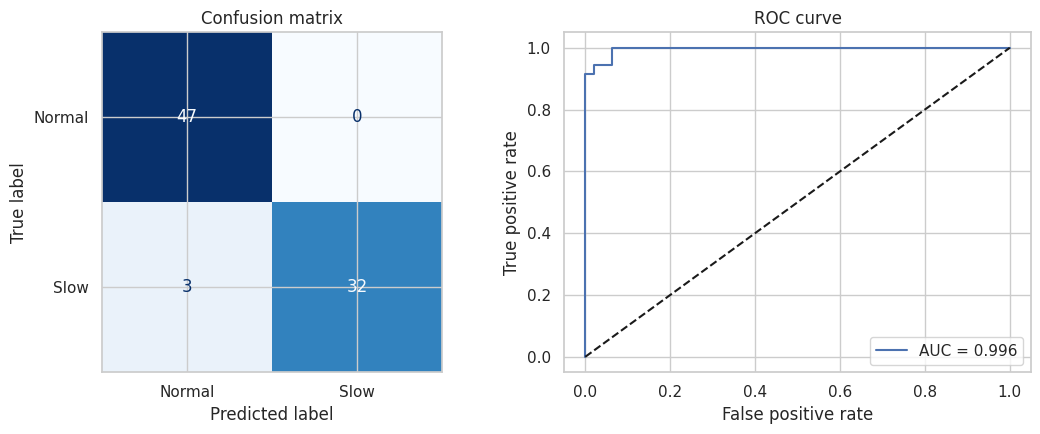

In [8]:
print(classification_report(y_test, pred1, target_names=['Normal', 'Slow']))

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred1), display_labels=['Normal', 'Slow']).plot(ax=ax[0], cmap='Blues', colorbar=False)
ax[0].set_title('Confusion matrix')
fpr, tpr, _ = roc_curve(y_test, prob1)
ax[1].plot(fpr, tpr, label=f'AUC = {roc_auc_score(y_test, prob1):.3f}'); ax[1].plot([0, 1], [0, 1], 'k--')
ax[1].set(title='ROC curve', xlabel='False positive rate', ylabel='True positive rate'); ax[1].legend()
plt.tight_layout(); plt.show()

In [9]:
# Overfitting check: a big gap between train and test means the model memorised the training data
print('Train accuracy:', round(accuracy_score(y_train, lr_model.predict(X_train)), 3))
print('Test  accuracy:', round(accuracy_score(y_test,  lr_model.predict(X_test)), 3))
print('Train F1      :', round(f1_score(y_train, lr_model.predict(X_train)), 3))
print('Test  F1      :', round(f1_score(y_test,  lr_model.predict(X_test)), 3))

Train accuracy: 0.938
Test  accuracy: 0.963
Train F1      : 0.926
Test  F1      : 0.955


## Step 7 — Cross-validation (more reliable)
The test set is small (60 rows). 5-fold cross-validation trains and tests 5 times on different parts of the training data and averages the results. The **± value** shows how much the score varies.

In [10]:
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
res = cross_validate(make_model(C=1), X_train, y_train, cv=cv, scoring=scoring)
pd.DataFrame({k: [res[f'test_{k}'].mean(), res[f'test_{k}'].std()] for k in scoring}, index=['mean', 'std']).T.round(3)

,mean,std
accuracy,0.917,0.013
precision,0.904,0.047
recall,0.906,0.075
f1,0.901,0.019
roc_auc,0.966,0.025


## Step 8 — Tune the model
Two settings matter:
* **C** — regularisation strength (small = simpler, less overfitting; large = tighter fit).
* **penalty** — `l2` (shrinks all weights) or `l1` (can switch useless features off completely).

We try every combination and keep the best **F1** (change `TUNE_SCORING` to `'recall'` if you mostly care about not missing slow learners).

In [11]:
TUNE_SCORING = 'f1'
param_grid = {
    'lr__C':       [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100],
    'lr__penalty': ['l2', 'l1'],
    'lr__solver':  ['liblinear'],      # supports both l1 and l2
}
search = GridSearchCV(make_model(), param_grid, cv=cv, scoring=TUNE_SCORING, n_jobs=-1)
search.fit(X_train, y_train)
print('Best settings :', search.best_params_)
print(f'Best CV {TUNE_SCORING}  :', round(search.best_score_, 3))
best_lr = search.best_estimator_

Best settings : {'lr__C': 0.3, 'lr__penalty': 'l1', 'lr__solver': 'liblinear'}
Best CV f1  : 0.908


In [12]:
m2, pred2, prob2 = evaluate(best_lr, X_test, y_test, '=== Test-set results (tuned model) ===')
pd.DataFrame({'First model': m1, 'Tuned model': m2}).round(3)

=== Test-set results (tuned model) ===


,score
Accuracy,0.963
Balanced Accuracy,0.957
Precision,1.000
Recall,0.914
F1,0.955
Specificity,1.000
ROC-AUC,0.993
MCC,0.927


TP=32 (slow caught)  FN=3 (slow missed)  FP=0 (false alarm)  TN=47


,First model,Tuned model
Accuracy,0.963,0.963
Balanced Accuracy,0.957,0.957
Precision,1.000,1.000
Recall,0.914,0.914
F1,0.955,0.955
Specificity,1.000,1.000
ROC-AUC,0.996,0.993
MCC,0.927,0.927


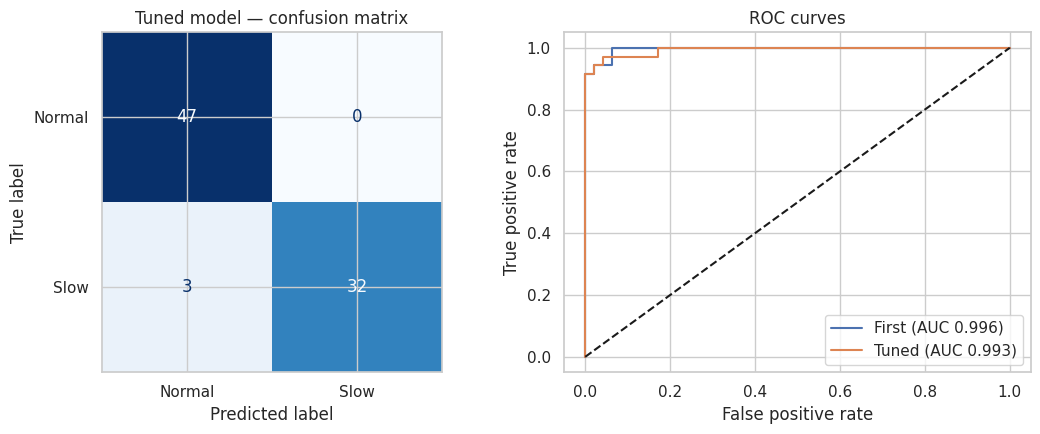

              precision    recall  f1-score   support

      Normal       0.94      1.00      0.97        47
        Slow       1.00      0.91      0.96        35

    accuracy                           0.96        82
   macro avg       0.97      0.96      0.96        82
weighted avg       0.97      0.96      0.96        82



In [13]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred2), display_labels=['Normal', 'Slow']).plot(ax=ax[0], cmap='Blues', colorbar=False)
ax[0].set_title('Tuned model — confusion matrix')
for p, lab in [(prob1, 'First'), (prob2, 'Tuned')]:
    f, t, _ = roc_curve(y_test, p); ax[1].plot(f, t, label=f'{lab} (AUC {roc_auc_score(y_test, p):.3f})')
ax[1].plot([0, 1], [0, 1], 'k--'); ax[1].set(title='ROC curves', xlabel='False positive rate', ylabel='True positive rate'); ax[1].legend()
plt.tight_layout(); plt.show()
print(classification_report(y_test, pred2, target_names=['Normal', 'Slow']))

## Step 9 — Understand the model
Logistic Regression is directly readable. Each feature gets a **coefficient** (on standardised data, so sizes are comparable):
* positive → pushes towards **Slow**, negative → pushes towards **Normal**
* **odds ratio** = e^coefficient: e.g. 2.0 means "a 1-standard-deviation increase in this feature doubles the odds of Slow".

,coefficient,odds_ratio
Log_Carry_Time,1.805,6.083
Non_Carry_Time,0.962,2.617
Hint_Requests,0.861,2.366
Log_Total_Time,0.691,1.995
Erasure_Count,0.008,1.008
Carry_Ratio,0.000,1.000
Operation_Type_Addition,0.000,1.000
Operation_Type_Multiplication,0.000,1.000
Operation_Type_Subtraction,0.000,1.000
Operation_Type_Division,-0.796,0.451


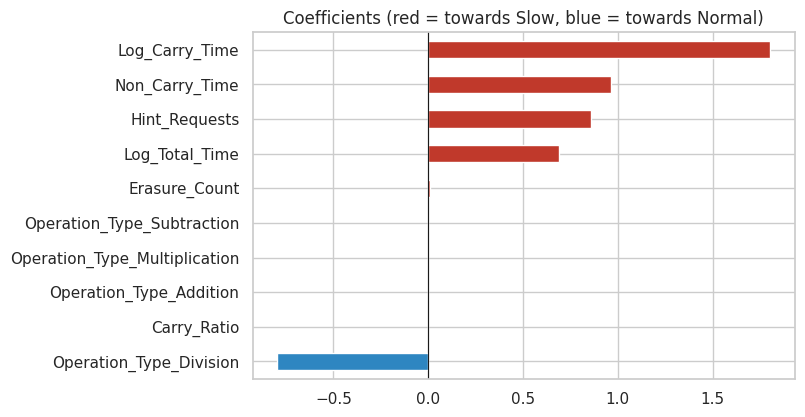

In [14]:
names = [n.split('__')[-1] for n in best_lr.named_steps['prep'].get_feature_names_out()]
coef = pd.Series(best_lr.named_steps['lr'].coef_[0], index=names)
table = pd.DataFrame({'coefficient': coef, 'odds_ratio': np.exp(coef)}).sort_values('coefficient', ascending=False).round(3)
display(table)

coef.sort_values().plot(kind='barh', figsize=(7, 4.5), color=['#c0392b' if v > 0 else '#2e86c1' for v in coef.sort_values()],
                        title='Coefficients (red = towards Slow, blue = towards Normal)')
plt.axvline(0, color='k', lw=.8); plt.show()

### Threshold tuning (optional)
By default, P(Slow) ≥ 0.5 means "Slow". Lowering the threshold catches more slow learners (higher Recall) at the cost of more false alarms (lower Precision). Pick the cut-off that suits how the result will be used.

In [15]:
th = pd.DataFrame([{'threshold': t, 'precision': precision_score(y_test, prob2 >= t, zero_division=0),
                    'recall': recall_score(y_test, prob2 >= t), 'f1': f1_score(y_test, prob2 >= t)}
                   for t in np.arange(0.1, 0.91, 0.1)]).round(3)
th

,threshold,precision,recall,f1
0,0.1,0.660,1.000,0.795
1,0.2,0.814,1.000,0.897
2,0.3,0.919,0.971,0.944
3,0.4,0.971,0.943,0.957
4,0.5,1.000,0.914,0.955
5,0.6,1.000,0.914,0.955
6,0.7,1.000,0.886,0.939
7,0.8,1.000,0.857,0.923
8,0.9,1.000,0.714,0.833


## Step 10 — Final check, save and download
The tuned model is **retrained on all rows** and saved. Your backend needs:
* `lr_slow_learner_model.joblib` — the model (scaling and encoding are inside it)
* `lr_model_metadata.json` — feature order, threshold, scikit-learn version, test scores

In [16]:
THRESHOLD = 0.5       # set to your chosen cut-off from the table above

final_model = make_model(**{k.replace('lr__', ''): v for k, v in search.best_params_.items()})
final_model.fit(X, y)

os.makedirs('export', exist_ok=True)
joblib.dump(final_model, 'export/lr_slow_learner_model.joblib')

import sklearn
meta = {'model': 'LogisticRegression', 'positive_class': 'Slow', 'threshold': THRESHOLD, 'use_hints': USE_HINTS,
        'best_params': {k: (v if isinstance(v, (int, float, str)) else str(v)) for k, v in search.best_params_.items()},
        'coefficients': {k: round(float(v), 4) for k, v in coef.items()}, 'intercept': round(float(best_lr.named_steps['lr'].intercept_[0]), 4),
        'features_required_in_order': FEATURES,
        'raw_inputs': ['Operation_Type', 'Total_Time', 'Carry_Over_Time', 'Erasure_Count', 'Hint_Requests'],
        'operation_types': sorted(df['Operation_Type'].unique().tolist()),
        'test_metrics': {k: round(float(v), 4) for k, v in m2.items()}, 'sklearn_version': sklearn.__version__}
json.dump(meta, open('export/lr_model_metadata.json', 'w'), indent=2)
print(json.dumps(meta, indent=2))

{
  "model": "LogisticRegression",
  "positive_class": "Slow",
  "threshold": 0.5,
  "use_hints": true,
  "best_params": {
    "lr__C": 0.3,
    "lr__penalty": "l1",
    "lr__solver": "liblinear"
  },
  "coefficients": {
    "Log_Total_Time": 0.6906,
    "Log_Carry_Time": 1.8055,
    "Erasure_Count": 0.0079,
    "Carry_Ratio": 0.0,
    "Non_Carry_Time": 0.9621,
    "Hint_Requests": 0.861,
    "Operation_Type_Addition": 0.0,
    "Operation_Type_Division": -0.7959,
    "Operation_Type_Multiplication": 0.0,
    "Operation_Type_Subtraction": 0.0
  },
  "intercept": 0.0,
  "features_required_in_order": [
    "Log_Total_Time",
    "Log_Carry_Time",
    "Erasure_Count",
    "Carry_Ratio",
    "Non_Carry_Time",
    "Hint_Requests",
    "Operation_Type"
  ],
  "raw_inputs": [
    "Operation_Type",
    "Total_Time",
    "Carry_Over_Time",
    "Erasure_Count",
    "Hint_Requests"
  ],
  "operation_types": [
    "Addition",
    "Division",
    "Multiplication",
    "Subtraction"
  ],
  "test_metri

In [17]:
# Try the saved model exactly as your backend will use it
def prepare_input(op, total_time, carry_time, erasures, hints=0):
    row = {'Operation_Type': op, 'Log_Total_Time': np.log1p(total_time), 'Log_Carry_Time': np.log1p(carry_time),
           'Erasure_Count': erasures, 'Hint_Requests': hints,
           'Carry_Ratio': carry_time / total_time if total_time else 0, 'Non_Carry_Time': total_time - carry_time}
    return pd.DataFrame([row])[meta['features_required_in_order']]

loaded = joblib.load('export/lr_slow_learner_model.joblib')
for case in [('Addition', 2.1, 2.1, 0, 0), ('Division', 70.0, 40.0, 2, 3)]:
    p = loaded.predict_proba(prepare_input(*case))[0, 1]
    print(case, '-> P(Slow) =', round(p, 3), '->', 'Slow' if p >= meta['threshold'] else 'Normal')

('Addition', 2.1, 2.1, 0, 0) -> P(Slow) = 0.009 -> Normal
('Division', 70.0, 40.0, 2, 3) -> P(Slow) = 0.998 -> Slow


In [18]:
import shutil
shutil.make_archive('lr_export', 'zip', 'export')
try:
    from google.colab import files
    files.download('lr_export.zip')
except ImportError:
    print('Saved lr_export.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Notes for your report / backend
* Install the **same scikit-learn version** in your backend as in `lr_model_metadata.json`.
* Scaling and one-hot encoding are inside the saved model, **but the log transform and the derived columns are not** — your backend must compute them exactly as `prepare_input` does (log1p of the two time columns, `Carry_Ratio`, `Non_Carry_Time`).
* Report the test scores above as your performance figures (they come from the model trained on 80%; the exported one is retrained on 100%).